In [2]:
import matplotlib.pyplot as plt
import numpy as np
import tables as tab
%matplotlib widget

## FUNCTIONS

In [3]:
from matplotlib.patches import Rectangle
DETECTOR_BOUNDS = {
    "x": (-400.0, 400.0),
    "y": (-425.0, 425.0),
    "z": (-300.0, 600.0),
}

ACTIVE_VOLUME_BOUNDS = {
    "x": (-338.5, 338.5),
    "y": (-334.0, 334.0),
    "z": (0,      300.0),
}

active_v_lower_bounds = np.array([av_bounds[0] for ax, av_bounds in ACTIVE_VOLUME_BOUNDS.items()])
active_v_upper_bounds = np.array([av_bounds[1] for ax, av_bounds in ACTIVE_VOLUME_BOUNDS.items()])
inside_xyz_bounds_by_margin = lambda point, margin : ((point - active_v_lower_bounds) > margin) & ((active_v_upper_bounds - point) > margin) 


def get_trajectory_start_end(trajectory_table_row : tab.tableextension.Row, exclude_interior_tracks=-1, exclude_y=-1):
    """Get the start and end points of each trajectory from the hdf5 table"""
    reco_track_point_bounds = DETECTOR_BOUNDS.copy()
    reco_track_point_bounds['x'] = (-345, 345) # The (lardon z) (larsoft x) values are computed from e drift times referenced to estimated t0 (actual track-crossing time). It should be impossible to get a (larsoft) x significantly outside active volume unless t0 estimation is wrong (if the first e- reached the anode "before the track even crossed"). 
    # Maybe the y and z bounds should also be stricter --> how does LARDON determine x_ini/end and y_ini/end? Would it be reasonable for these values to be outside detector volume?
    # LArSoft (x,y,z) <---> LARDON (z,x,y)
    coords = {}
    coords["x_ini"], coords["y_ini"], coords["z_ini"] = trajectory_table_row['z_ini_corrected'], trajectory_table_row['x_ini'], trajectory_table_row['y_ini']  
    coords["x_end"], coords["y_end"], coords["z_end"] = trajectory_table_row['z_end_corrected'], trajectory_table_row['x_end'], trajectory_table_row['y_end']  

    is_paired = (trajectory_table_row["cathode_crosser_ID"] != -1)
    if is_paired:
        # The "cc_"-labelled tracks are supposed to be the ones in the upper volume.  
        coords["cc_x_ini"], coords["cc_y_ini"], coords["cc_z_ini"] = trajectory_table_row['cc_z_ini_corrected'], trajectory_table_row['cc_x_ini'], trajectory_table_row['cc_y_ini'] 
        coords["cc_x_end"], coords["cc_y_end"], coords["cc_z_end"] = trajectory_table_row['cc_z_end_corrected'], trajectory_table_row['cc_x_end'], trajectory_table_row['cc_y_end'] 

        ## Perform "quality control" tests
        # If any of the four points lie outside the allowed bounds, exit.
        for ax, bounds in reco_track_point_bounds.items():
            if np.any( [ ((coords[k] < bounds[0]) or (coords[k] > bounds[1])) for k in (f"cc_{ax}_ini",f"cc_{ax}_end",f"{ax}_ini",f"{ax}_end") ] ):
                return None

        # If the "cc_" (upper volume) track starts _below_ the start of the paired *lower* volume track (or ends below its end), something is wrong.
        # Basically if one track completely overlaps vertically with the other or the tracks are "on the wrong side", move on.    
        if (coords["cc_x_ini"] < coords["x_ini"]) or (coords["cc_x_end"] < coords["x_end"]):
            return None
        # Note: at this point the cc_ini --> end distance ought to be the largest among the four points involved. Can check this externally 
        start = np.array([ coords['cc_x_ini'], coords['cc_y_ini'], coords['cc_z_ini'] ])
        end   = np.array([ coords['x_end'],    coords['y_end'],    coords['z_end'] ])
        # return start, end
    else:
        # If any of the four points lie outside the allowed bounds, exit.
        for ax, bounds in reco_track_point_bounds.items():
            if np.any( [ ((coords[k] < bounds[0]) or (coords[k] > bounds[1])) for k in (f"{ax}_ini",f"{ax}_end") ] ):
                return None

        start = np.array([ coords['x_ini'], coords['y_ini'], coords['z_ini'] ])
        end   = np.array([ coords['x_end'], coords['y_end'], coords['z_end'] ])
        # return start, end

    if exclude_interior_tracks < 0 and exclude_y < 0:
        return start, end
    else:
        if exclude_interior_tracks > 0:
            start_in_av_interior = np.all(inside_xyz_bounds_by_margin(start, exclude_interior_tracks))
            end_in_av_interior   = np.all(inside_xyz_bounds_by_margin(end, exclude_interior_tracks))  
            if start_in_av_interior or end_in_av_interior:
                return None 
            
        if exclude_y > 0:
            if (np.abs(start[1]) <= exclude_y) or (np.abs(end[1]) <= exclude_y):
                return None
        
    return start, end


def project_segment_to_detector_bounds(start, end, flipped=False):
    """Project a trajectory's start and end points to the detector bounds"""
    start, end = np.array(start), np.array(end) # just in case
    axes = ("x", "y", "z")
    # First try projecting to x boundary plane, then y boundary plane, then z boundary plane.
    for i, ax in enumerate(axes):
        planes = DETECTOR_BOUNDS[ax]
        end_target_plane = planes[0] if end[i] < start[i] else planes[1]
        tentative_proj_end = end + ((end_target_plane - end[i])/(end[i] - start[i]))*(end - start)

        # if the projection onto the x(y,z) boundary plane falls outside the y(z,x) or z(x,y) boundaries, try projecting onto another boundary. One of them has to work. 
        bounded1 = DETECTOR_BOUNDS[axes[i-1]][0] <= tentative_proj_end[i-1] <= DETECTOR_BOUNDS[axes[i-1]][1] 
        bounded2 = DETECTOR_BOUNDS[axes[i-2]][0] <= tentative_proj_end[i-2] <= DETECTOR_BOUNDS[axes[i-2]][1]
        if (not bounded1) or (not bounded2):
            continue
        else:
            proj_end = tentative_proj_end
    if not flipped:
        proj_start = project_segment_to_detector_bounds(end, start, flipped=True)
        return proj_start, proj_end
    else:
        return proj_end


def plot_detector_slices(sx, sy, sz, ex, ey, ez, nslices, ch=3, cw=3.2, bounds_to_use=DETECTOR_BOUNDS, fixed_lims=False):
    plt.close()
    fig, axs = plt.subplots(nslices, 3, figsize=(3*cw, ch*nslices), layout="constrained", squeeze=False, sharex=True)
    x_slice_bounds = np.linspace(bounds_to_use['x'][0], bounds_to_use['x'][1], nslices+1)
    y_slice_bounds = np.linspace(bounds_to_use['y'][0], bounds_to_use['y'][1], nslices+1)
    z_slice_bounds = np.linspace(bounds_to_use['z'][0], bounds_to_use['z'][1], nslices+1)

    for i in range(nslices):
        sx_slice_mask = (sx >= x_slice_bounds[i])&(sx <= x_slice_bounds[i+1])
        ex_slice_mask = (ex >= x_slice_bounds[i])&(ex <= x_slice_bounds[i+1])
        sy_slice_mask = (sy >= y_slice_bounds[i])&(sy <= y_slice_bounds[i+1])
        ey_slice_mask = (ey >= y_slice_bounds[i])&(ey <= y_slice_bounds[i+1])
        sz_slice_mask = (sz >= z_slice_bounds[i])&(sz <= z_slice_bounds[i+1])
        ez_slice_mask = (ez >= z_slice_bounds[i])&(ez <= z_slice_bounds[i+1])
        
        axs[i,0].set_title(f"x = [{x_slice_bounds[i]:.1f}, {x_slice_bounds[i+1]:.1f}]",fontsize="medium")
        if i == nslices-1:
            axs[i,0].set_xlabel("y", fontsize=11)
        axs[i,0].set_ylabel("z", fontsize=11)
        axs[i,0].plot(sy[sx_slice_mask], sz[sx_slice_mask], ".", color="pink", ms=2, mew=0, label="Ini", alpha=0.7)
        axs[i,0].plot(ey[ex_slice_mask], ez[ex_slice_mask], ".", color="yellow", ms=2, mew=0, label="End", alpha=0.7)
        axs[i,0].plot([ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][0]], 
                      "--", color="olive")

        axs[i,1].set_title(f"y = [{y_slice_bounds[i]:.1f}, {y_slice_bounds[i+1]:.1f}]",fontsize="medium")
        axs[i,1].set_xlabel("z", fontsize=11)
        axs[i,1].set_ylabel("x", fontsize=11)
        axs[i,1].plot(sz[sy_slice_mask], sx[sy_slice_mask], ".", color="pink", ms=2, mew=0, label="Ini", alpha=0.7)
        axs[i,1].plot(ez[ey_slice_mask], ex[ey_slice_mask], ".", color="yellow", ms=2, mew=0, label="End", alpha=0.7)
        axs[i,1].plot([ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][0]], 
                      "--", color="olive")

        axs[i,2].set_title(f"z = [{z_slice_bounds[i]:.1f}, {z_slice_bounds[i+1]:.1f}]",fontsize="medium")
        axs[i,2].set_xlabel("y", fontsize=11)
        axs[i,2].set_ylabel("x", fontsize=11)
        axs[i,2].plot(sy[sz_slice_mask], sx[sz_slice_mask], ".", color="pink", ms=2, mew=0, label="Ini", alpha=0.7)
        axs[i,2].plot(ey[ez_slice_mask], ex[ez_slice_mask], ".", color="yellow", ms=2, mew=0, label="End", alpha=0.7)
        axs[i,2].plot([ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][0]], 
                      "--", color="olive")

        if fixed_lims:
            m = 50
            axs[i,0].set_xlim((ACTIVE_VOLUME_BOUNDS["y"][0]-m, ACTIVE_VOLUME_BOUNDS["y"][1]+m))
            axs[i,0].set_ylim((ACTIVE_VOLUME_BOUNDS["z"][0]-m, ACTIVE_VOLUME_BOUNDS["z"][1]+m))
            axs[i,1].set_xlim((ACTIVE_VOLUME_BOUNDS["z"][0]-m, ACTIVE_VOLUME_BOUNDS["z"][1]+m))
            axs[i,1].set_ylim((ACTIVE_VOLUME_BOUNDS["x"][0]-m, ACTIVE_VOLUME_BOUNDS["x"][1]+m))
            axs[i,2].set_xlim((ACTIVE_VOLUME_BOUNDS["y"][0]-m, ACTIVE_VOLUME_BOUNDS["y"][1]+m))
            axs[i,2].set_ylim((ACTIVE_VOLUME_BOUNDS["x"][0]-m, ACTIVE_VOLUME_BOUNDS["x"][1]+m))
        
def plot_detector_slices_T(sx, sy, sz, ex, ey, ez, nslices, ch=3, cw=3.2, margin=0, bounds_to_use=DETECTOR_BOUNDS, fixed_lims=False):
    plt.close()
    fig, axs = plt.subplots(3, nslices, figsize=(cw*nslices, 3*ch), layout="constrained", squeeze=False)
    x_slice_bounds = np.linspace(bounds_to_use['x'][0], bounds_to_use['x'][1], nslices+1)
    y_slice_bounds = np.linspace(bounds_to_use['y'][0], bounds_to_use['y'][1], nslices+1)
    z_slice_bounds = np.linspace(bounds_to_use['z'][0], bounds_to_use['z'][1], nslices+1)

    for i in range(nslices):
        sx_slice_mask = (sx >= x_slice_bounds[i])&(sx <= x_slice_bounds[i+1])
        ex_slice_mask = (ex >= x_slice_bounds[i])&(ex <= x_slice_bounds[i+1])
        sy_slice_mask = (sy >= y_slice_bounds[i])&(sy <= y_slice_bounds[i+1])
        ey_slice_mask = (ey >= y_slice_bounds[i])&(ey <= y_slice_bounds[i+1])
        sz_slice_mask = (sz >= z_slice_bounds[i])&(sz <= z_slice_bounds[i+1])
        ez_slice_mask = (ez >= z_slice_bounds[i])&(ez <= z_slice_bounds[i+1])
        
        axs[0,i].set_title(f"x = [{x_slice_bounds[i]:.1f}, {x_slice_bounds[i+1]:.1f}]")
        axs[0,i].set_xlabel("y")
        axs[0,i].set_ylabel("z")
        axs[0,i].plot(sy[sx_slice_mask], sz[sx_slice_mask], ".", color="pink", ms=2, mew=0, label="Ini")
        axs[0,i].plot(ey[ex_slice_mask], ez[ex_slice_mask], ".", color="yellow", ms=2, mew=0, label="End")
        axs[0,i].plot([ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][0]], 
                      "--", color="olive",label="A.V. bounds")
        if margin>0:
            axs[0,i].add_patch(Rectangle( (ACTIVE_VOLUME_BOUNDS["y"][0]+margin, ACTIVE_VOLUME_BOUNDS["z"][0]+margin), 
                                           ACTIVE_VOLUME_BOUNDS["y"][1] - ACTIVE_VOLUME_BOUNDS["y"][0] - (2*margin),  
                                           ACTIVE_VOLUME_BOUNDS["z"][1] - ACTIVE_VOLUME_BOUNDS["z"][0] - (2*margin),
                                           facecolor='silver', edgecolor='grey', hatch='/', hatch_linewidth=1, alpha=0.2, zorder=100, label=f"in A.V. by {margin}cm" ) )   
                
        axs[1,i].set_title(f"y = [{y_slice_bounds[i]:.1f}, {y_slice_bounds[i+1]:.1f}]")
        axs[1,i].set_xlabel("z")
        axs[1,i].set_ylabel("x")
        axs[1,i].plot(sz[sy_slice_mask], sx[sy_slice_mask], ".", color="pink", ms=2, mew=0, label="Ini")
        axs[1,i].plot(ez[ey_slice_mask], ex[ey_slice_mask], ".", color="yellow", ms=2, mew=0, label="End")
        axs[1,i].plot([ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][0]], 
                      "--", color="olive",label="A.V. bounds")
        if margin>0:
            axs[1,i].add_patch(Rectangle( (ACTIVE_VOLUME_BOUNDS["z"][0]+margin, ACTIVE_VOLUME_BOUNDS["x"][0]+margin), 
                                           ACTIVE_VOLUME_BOUNDS["z"][1] - ACTIVE_VOLUME_BOUNDS["z"][0] - (2*margin),  
                                           ACTIVE_VOLUME_BOUNDS["x"][1] - ACTIVE_VOLUME_BOUNDS["x"][0] - (2*margin),
                                           facecolor='silver', edgecolor='grey', hatch='/', hatch_linewidth=1, alpha=0.2, zorder=100, label=f"in A.V. by {margin}cm" ) )   
        
        axs[2,i].set_title(f"z = [{z_slice_bounds[i]:.1f}, {z_slice_bounds[i+1]:.1f}]")
        axs[2,i].set_xlabel("y")
        axs[2,i].set_ylabel("x")
        axs[2,i].plot(sy[sz_slice_mask], sx[sz_slice_mask], ".", color="pink", ms=2, mew=0, label="Ini")
        axs[2,i].plot(ey[ez_slice_mask], ex[ez_slice_mask], ".", color="yellow", ms=2, mew=0, label="End")
        axs[2,i].plot([ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][0]], 
                      "--", color="olive",label="A.V. bounds")
        if margin>0:
            axs[2,i].add_patch(Rectangle( (ACTIVE_VOLUME_BOUNDS["y"][0]+margin, ACTIVE_VOLUME_BOUNDS["x"][0]+margin), 
                                           ACTIVE_VOLUME_BOUNDS["y"][1] - ACTIVE_VOLUME_BOUNDS["y"][0] - (2*margin),  
                                           ACTIVE_VOLUME_BOUNDS["x"][1] - ACTIVE_VOLUME_BOUNDS["x"][0] - (2*margin),
                                           facecolor='silver', edgecolor='grey', hatch='/', hatch_linewidth=1, alpha=0.2, zorder=100, label=f"in A.V. by {margin}cm" ) )   

        # axs[0,i].legend(fontsize="small", markerscale=3, loc=(1.1, 0.45))
        # axs[1,i].legend(fontsize="small", markerscale=3, loc=(1.1, 0.45))
        # axs[2,i].legend(fontsize="small", markerscale=3, loc=(1.1, 0.45))

        if fixed_lims:
            m = 50
            axs[0,i].set_xlim((ACTIVE_VOLUME_BOUNDS["y"][0]-m, ACTIVE_VOLUME_BOUNDS["y"][1]+m))
            axs[0,i].set_ylim((ACTIVE_VOLUME_BOUNDS["z"][0]-m, ACTIVE_VOLUME_BOUNDS["z"][1]+m))
            axs[1,i].set_xlim((ACTIVE_VOLUME_BOUNDS["z"][0]-m, ACTIVE_VOLUME_BOUNDS["z"][1]+m))
            axs[1,i].set_ylim((ACTIVE_VOLUME_BOUNDS["x"][0]-m, ACTIVE_VOLUME_BOUNDS["x"][1]+m))
            axs[2,i].set_xlim((ACTIVE_VOLUME_BOUNDS["y"][0]-m, ACTIVE_VOLUME_BOUNDS["y"][1]+m))
            axs[2,i].set_ylim((ACTIVE_VOLUME_BOUNDS["x"][0]-m, ACTIVE_VOLUME_BOUNDS["x"][1]+m))
            

        
    # fig.show()
    
def plot_detector_slices_alt(sx, sy, sz, ex, ey, ez, nslices, ch=4, cw=4.5, bounds_to_use=DETECTOR_BOUNDS, fixed_lims=False, step=1, x_only=False):
    plt.close()
    assert len(sx) == len(sy) == len(sz) == len(ex) == len(ey) == len(ez)  
    if x_only:
        fig, axs = plt.subplots(nslices, 1, figsize=(1*cw, ch*nslices), layout="constrained", squeeze=False, sharex=True)
    else:
        fig, axs = plt.subplots(nslices, 3, figsize=(3*cw, ch*nslices), layout="constrained", squeeze=False, sharex=True)
    x_slice_bounds = np.linspace(bounds_to_use['x'][0], bounds_to_use['x'][1], nslices+1)
    y_slice_bounds = np.linspace(bounds_to_use['y'][0], bounds_to_use['y'][1], nslices+1)
    z_slice_bounds = np.linspace(bounds_to_use['z'][0], bounds_to_use['z'][1], nslices+1)

    for i in range(nslices):
        sx_slice_mask = (sx >= x_slice_bounds[i])&(sx <= x_slice_bounds[i+1])
        ex_slice_mask = (ex >= x_slice_bounds[i])&(ex <= x_slice_bounds[i+1])
        sy_slice_mask = (sy >= y_slice_bounds[i])&(sy <= y_slice_bounds[i+1])
        ey_slice_mask = (ey >= y_slice_bounds[i])&(ey <= y_slice_bounds[i+1])
        sz_slice_mask = (sz >= z_slice_bounds[i])&(sz <= z_slice_bounds[i+1])
        ez_slice_mask = (ez >= z_slice_bounds[i])&(ez <= z_slice_bounds[i+1])

        for t in range(0, len(sx), step):
            ## IF this track's start and end x is within the slice, plot its yz view. 
            if sx_slice_mask[t] and ex_slice_mask[t]:
                axs[i,0].plot([sy[t], ey[t]], [sz[t], ez[t]], ls="-", lw=0.1, color="blue", alpha=0.1)

            if not x_only:
                ## IF this track's start and end y is within the slice, plot its zx view. 
                if sy_slice_mask[t] and ey_slice_mask[t]:
                    axs[i,1].plot([sz[t], ez[t]], [sx[t], ex[t]], ls="-", lw=0.1, color="blue", alpha=0.1)
                ## IF this track's start and end z is within the slice, plot its yx view. 
                if sz_slice_mask[t] and ez_slice_mask[t]:
                    axs[i,2].plot([sy[t], ey[t]], [sx[t], ex[t]], ls="-", lw=0.1, color="blue", alpha=0.1)
        
        axs[i,0].set_title(f"x = [{x_slice_bounds[i]:.1f}, {x_slice_bounds[i+1]:.1f}]",fontsize="medium")
        if i == nslices-1:
            axs[i,0].set_xlabel("y", fontsize=11)
        axs[i,0].set_ylabel("z", fontsize=11)
        axs[i,0].plot([ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][0]], 
                      "--", color="olive")
        if x_only:
            continue

        axs[i,1].set_title(f"y = [{y_slice_bounds[i]:.1f}, {y_slice_bounds[i+1]:.1f}]",fontsize="medium")
        axs[i,1].set_xlabel("z", fontsize=11)
        axs[i,1].set_ylabel("x", fontsize=11)
        axs[i,1].plot([ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][0], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][1], ACTIVE_VOLUME_BOUNDS["z"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][0]], 
                      "--", color="olive")

        axs[i,2].set_title(f"z = [{z_slice_bounds[i]:.1f}, {z_slice_bounds[i+1]:.1f}]",fontsize="medium")
        axs[i,2].set_xlabel("y", fontsize=11)
        axs[i,2].set_ylabel("x", fontsize=11)
        axs[i,2].plot([ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][0]], 
                      [ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][0]], 
                      "--", color="olive")

        if fixed_lims:
            m = 50
            axs[i,0].set_xlim((ACTIVE_VOLUME_BOUNDS["y"][0]-m, ACTIVE_VOLUME_BOUNDS["y"][1]+m))
            axs[i,0].set_ylim((ACTIVE_VOLUME_BOUNDS["z"][0]-m, ACTIVE_VOLUME_BOUNDS["z"][1]+m))
            axs[i,1].set_xlim((ACTIVE_VOLUME_BOUNDS["z"][0]-m, ACTIVE_VOLUME_BOUNDS["z"][1]+m))
            axs[i,1].set_ylim((ACTIVE_VOLUME_BOUNDS["x"][0]-m, ACTIVE_VOLUME_BOUNDS["x"][1]+m))
            axs[i,2].set_xlim((ACTIVE_VOLUME_BOUNDS["y"][0]-m, ACTIVE_VOLUME_BOUNDS["y"][1]+m))
            axs[i,2].set_ylim((ACTIVE_VOLUME_BOUNDS["x"][0]-m, ACTIVE_VOLUME_BOUNDS["x"][1]+m))

In [3]:
trk_info_file = tab.open_file("out_39273_a_ac_ca_aca_angles.h5")

In [4]:
trk_info_table = trk_info_file.root.output
trk_info_table

/output (Table(np.int64(135929),)) np.str_('Output (test)')
  description := {
  "filename": StringCol(itemsize=32, shape=(), dflt=np.bytes_(b''), pos=0),
  "event": UInt32Col(shape=(), dflt=np.uint32(0), pos=1),
  "trigger": UInt32Col(shape=(), dflt=np.uint32(0), pos=2),
  "cluster_ID": Int32Col(shape=(), dflt=np.int32(0), pos=3),
  "ID": UInt32Col(shape=(), dflt=np.uint32(0), pos=4),
  "cathode_crosser_ID": Int32Col(shape=(), dflt=np.int32(0), pos=5),
  "total_npe": Float64Col(shape=(), dflt=np.float64(0.0), pos=6),
  "cluster_size": UInt32Col(shape=(), dflt=np.uint32(0), pos=7),
  "cc_is_anode_crosser": BoolCol(shape=(), dflt=np.False_, pos=8),
  "is_anode_crosser": BoolCol(shape=(), dflt=np.False_, pos=9),
  "cc_is_cathode_crosser": BoolCol(shape=(), dflt=np.False_, pos=10),
  "is_cathode_crosser": BoolCol(shape=(), dflt=np.False_, pos=11),
  "cc_x_ini": Float32Col(shape=(), dflt=np.float32(0.0), pos=12),
  "x_ini": Float32Col(shape=(), dflt=np.float32(0.0), pos=13),
  "cc_x_end": 

In [5]:
start_points = np.empty((0, 3))
end_points   = np.empty((0, 3))

start_angles = np.empty((0, 2))
end_angles   = np.empty((0, 2))

proj_start_points = np.empty((0, 3))
proj_end_points   = np.empty((0, 3))

cathode_crosser = []

excl_int_30_mask = [] 
excl_int_10_mask = [] 

excl_y_mask = [] 

for track in trk_info_table:
    start_end_tuple = get_trajectory_start_end(track)
    start_end_tuple_int_excl_30 = get_trajectory_start_end(track, exclude_interior_tracks=30) # MORE LENIENT, ONLY EXCLUDE IF POINT IS OVER 30 cm INSIDE AV
    start_end_tuple_int_excl_10 = get_trajectory_start_end(track, exclude_interior_tracks=10)

    start_end_tuple_int_excl_10_y_excl_12 = get_trajectory_start_end(track, 10, 12)

    if start_end_tuple is None:
        continue

    excl_int_30_mask.append(not (start_end_tuple_int_excl_30 is None)) # will select a track only if it was not excluded by a 30cm margin. 
    excl_int_10_mask.append(not (start_end_tuple_int_excl_10 is None))

    excl_y_mask.append(not (start_end_tuple_int_excl_10_y_excl_12 is None))

    start_points = np.append(start_points, [start_end_tuple[0]], axis=0)
    end_points   = np.append(end_points,   [start_end_tuple[1]], axis=0)

    start_angles = np.append(start_angles, [[(track['theta_ini'] if track['cathode_crosser_ID'] == -1 else track['cc_theta_ini']), 
                                                 (track['phi_ini'] if track['cathode_crosser_ID'] == -1 else track['cc_phi_ini'])]], axis=0)
    end_angles   = np.append(end_angles,   [[track['theta_end'], track['phi_end']]], axis=0)

    cathode_crosser.append( (track['cathode_crosser_ID'] != -1) )

    entry_point, exit_point = project_segment_to_detector_bounds(*start_end_tuple)
    proj_start_points = np.append(proj_start_points, [entry_point], axis=0)
    proj_end_points   = np.append(proj_end_points,   [exit_point],  axis=0)

cathode_crosser = np.array(cathode_crosser)
excl_int_30_mask = np.array(excl_int_30_mask)
excl_int_10_mask = np.array(excl_int_10_mask)
excl_y_mask = np.array(excl_y_mask)


C:\Users\sansk\AppData\Local\Temp\ipykernel_35204\2125204854.py:83: RuntimeWarning: divide by zero encountered in scalar divide
  tentative_proj_end = end + ((end_target_plane - end[i])/(end[i] - start[i]))*(end - start)
C:\Users\sansk\AppData\Local\Temp\ipykernel_35204\2125204854.py:83: RuntimeWarning: invalid value encountered in multiply
  tentative_proj_end = end + ((end_target_plane - end[i])/(end[i] - start[i]))*(end - start)


In [54]:
anode_only_crosser_ct = 0
anode_only_crosser_oob_ct = 0

anode_cathode_crosser_ct = 0
anode_cathode_crosser_oob_ct = 0
anode_cathode_crosser_bad_join_ct = 0

bad_join_cc_ini = []
bad_join_cc_end = []
bad_join_ini = []
bad_join_end = []

for track in trk_info_table:
    reco_track_point_bounds = DETECTOR_BOUNDS.copy()
    reco_track_point_bounds['x'] = (-345, 345) # The (lardon z) (larsoft x) values are computed from e drift times referenced to estimated t0 (actual track-crossing time). It should be impossible to get a (larsoft) x significantly outside active volume unless t0 estimation is wrong (if the first e- reached the anode "before the track even crossed"). 
    # Maybe the y and z bounds should also be stricter --> how does LARDON determine x_ini/end and y_ini/end? Would it be reasonable for these values to be outside detector volume?
    # LArSoft (x,y,z) <---> LARDON (z,x,y)
    coords = {}
    coords["x_ini"], coords["y_ini"], coords["z_ini"] = track['z_ini_corrected'], track['x_ini'], track['y_ini']  
    coords["x_end"], coords["y_end"], coords["z_end"] = track['z_end_corrected'], track['x_end'], track['y_end']  

    is_paired = (track["cathode_crosser_ID"] != -1)
    if is_paired:
        anode_cathode_crosser_ct += 1
        # The "cc_"-labelled tracks are supposed to be the ones in the upper volume.  
        coords["cc_x_ini"], coords["cc_y_ini"], coords["cc_z_ini"] = track['cc_z_ini_corrected'], track['cc_x_ini'], track['cc_y_ini'] 
        coords["cc_x_end"], coords["cc_y_end"], coords["cc_z_end"] = track['cc_z_end_corrected'], track['cc_x_end'], track['cc_y_end'] 

        ## Perform "quality control" tests
        # If any of the four points lie outside the allowed bounds, exit.
        exit_flag = False
        for ax, bounds in reco_track_point_bounds.items():
            if np.any( [ ((coords[k] < bounds[0]) or (coords[k] > bounds[1])) for k in (f"cc_{ax}_ini",f"cc_{ax}_end",f"{ax}_ini",f"{ax}_end") ] ):
                exit_flag = True
        if exit_flag: 
            anode_cathode_crosser_oob_ct += 1
            continue

        # If the "cc_" (upper volume) track starts _below_ the start of the paired *lower* volume track (or ends below its end), something is wrong.
        # Basically if one track completely overlaps vertically with the other or the tracks are "on the wrong side", move on.    
        if (coords["cc_x_ini"] < coords["x_ini"]) or (coords["cc_x_end"] < coords["x_end"]):
            anode_cathode_crosser_bad_join_ct += 1
            bad_join_cc_ini.append([coords["cc_x_ini"], coords["cc_y_ini"], coords["cc_z_ini"]])
            bad_join_cc_end.append([coords["cc_x_end"], coords["cc_y_end"], coords["cc_z_end"]])
            bad_join_ini.append([coords["x_ini"], coords["y_ini"], coords["z_ini"]])
            bad_join_end.append([coords["x_end"], coords["y_end"], coords["z_end"]])
            continue
        # Note: at this point the cc_ini --> end distance ought to be the largest among the four points involved. Can check this externally 
    else:
        anode_only_crosser_ct += 1
        # If any of the four points lie outside the allowed bounds, exit.
        exit_flag = False
        for ax, bounds in reco_track_point_bounds.items():
            if np.any( [ ((coords[k] < bounds[0]) or (coords[k] > bounds[1])) for k in (f"{ax}_ini",f"{ax}_end") ] ):
                exit_flag = True
        if exit_flag: 
            anode_only_crosser_oob_ct += 1
            continue

anode_only_crosser_filt_ct = anode_only_crosser_ct - anode_only_crosser_oob_ct
anode_cathode_crosser_filt_ct = anode_cathode_crosser_ct - anode_cathode_crosser_oob_ct - anode_cathode_crosser_bad_join_ct

print("No. of selected tracks", anode_only_crosser_ct + anode_cathode_crosser_ct)
print("-->filtered for oob", anode_only_crosser_oob_ct+anode_cathode_crosser_oob_ct)
print("-->filtered for bad join", anode_cathode_crosser_bad_join_ct)
print("-->remaining", anode_only_crosser_filt_ct + anode_cathode_crosser_filt_ct)

print("No. of selected anode-only tracks", anode_only_crosser_ct)
print("-->filtered for oob", anode_only_crosser_oob_ct)
print("-->remaining", anode_only_crosser_filt_ct)

print("No. of selected anode-cathode tracks", anode_cathode_crosser_ct)
print("-->filtered for oob", anode_cathode_crosser_oob_ct)
print("-->filtered for bad join", anode_cathode_crosser_bad_join_ct)
print("-->remaining", anode_cathode_crosser_filt_ct)

bad_join_cc_ini = np.array(bad_join_cc_ini)
bad_join_cc_end = np.array(bad_join_cc_end)
bad_join_ini = np.array(bad_join_ini)
bad_join_end = np.array(bad_join_end)


No. of selected tracks 135929
-->filtered for oob 14407
-->filtered for bad join 4
-->remaining 121518
No. of selected anode-only tracks 124343
-->filtered for oob 13363
-->remaining 110980
No. of selected anode-cathode tracks 11586
-->filtered for oob 1044
-->filtered for bad join 4
-->remaining 10538


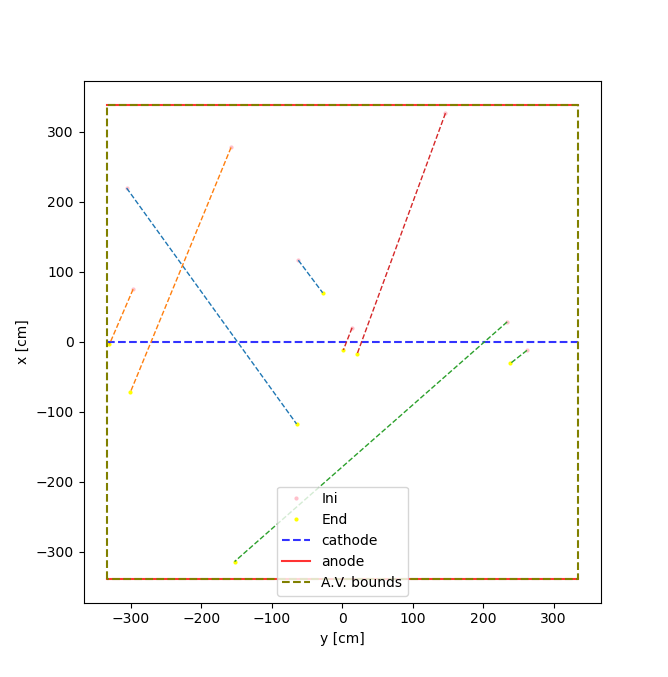

In [94]:
plt.figure(figsize=(6.68, 6.77))
plt.xlabel("y [cm]")
plt.ylabel("x [cm]")
plt.plot(bad_join_cc_ini[:, 1], bad_join_cc_ini[:, 0], ".", color="pink", ms=6, mew=0, label="Ini")
plt.plot(bad_join_ini[:, 1], bad_join_ini[:, 0],       ".", color="pink", ms=6, mew=0)
plt.plot(bad_join_cc_end[:, 1], bad_join_cc_end[:, 0], ".", color="yellow", ms=6, mew=0, label="End")
plt.plot(bad_join_end[:, 1], bad_join_end[:, 0],       ".", color="yellow", ms=6, mew=0)

plt.plot([-334, 334], [0, 0], "--", color="blue", alpha=0.8, label="cathode")
plt.plot([-334, 334], [338.5, 338.5],   "-", color="red", alpha=0.8, label="anode")
plt.plot([-334, 334], [-338.5, -338.5], "-", color="red", alpha=0.8)

for i in range(4):
    plt.plot([bad_join_cc_ini[i, 1], bad_join_cc_end[i, 1]], [bad_join_cc_ini[i, 0], bad_join_cc_end[i, 0]], lw=1, ls="--", color=f"C{i}")
    plt.plot([bad_join_ini[i, 1], bad_join_end[i, 1]], [bad_join_ini[i, 0], bad_join_end[i, 0]], lw=1, ls="--", color=f"C{i}")
plt.plot([ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][0], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][1], ACTIVE_VOLUME_BOUNDS["y"][0]], 
         [ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][1], ACTIVE_VOLUME_BOUNDS["x"][0], ACTIVE_VOLUME_BOUNDS["x"][0]], 
         "--", color="olive",label="A.V. bounds")
plt.legend()


In [6]:
print(len(start_points))
print(len(end_points))
print(len(start_angles))
print(len(end_angles))

print(len(cathode_crosser))
print(cathode_crosser.sum())

print()
print(len(excl_int_30_mask))
print(excl_int_30_mask.sum())
print(len(excl_int_10_mask))
print(excl_int_10_mask.sum())
print(len(excl_y_mask))
print(excl_y_mask.sum())
print()

assert np.all(start_points[:, 0] > end_points[:, 0])

print( start_points[~cathode_crosser].shape )

121518
121518
121518
121518
121518
10538

121518
83892
121518
62154
121518
59208

(110980, 3)


## Unprojected Slice Plots

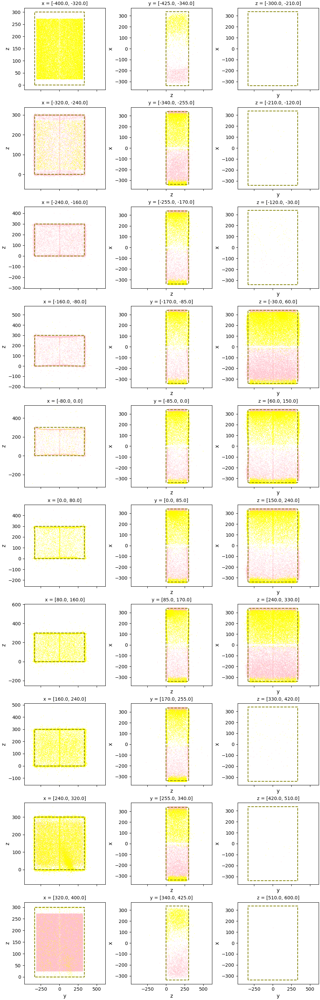

In [10]:
plot_detector_slices(start_points[~cathode_crosser][:,0], start_points[~cathode_crosser][:,1], start_points[~cathode_crosser][:,2], 
                     end_points[~cathode_crosser][:,0], end_points[~cathode_crosser][:,1], end_points[~cathode_crosser][:,2], 10)

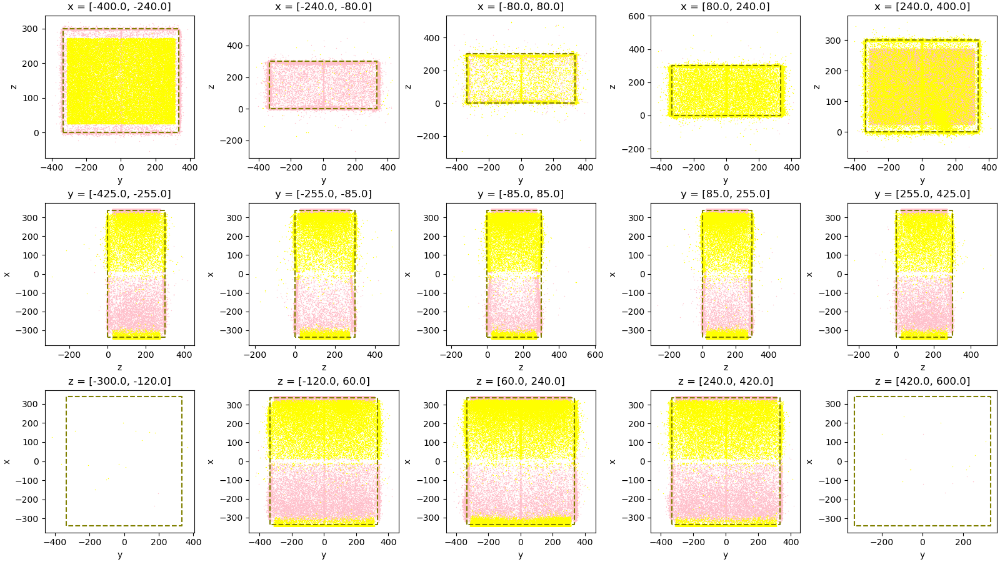

In [11]:
plot_detector_slices_T(start_points[~cathode_crosser][:,0], start_points[~cathode_crosser][:,1], start_points[~cathode_crosser][:,2], 
                     end_points[~cathode_crosser][:,0], end_points[~cathode_crosser][:,1], end_points[~cathode_crosser][:,2], 5)

40506
121518


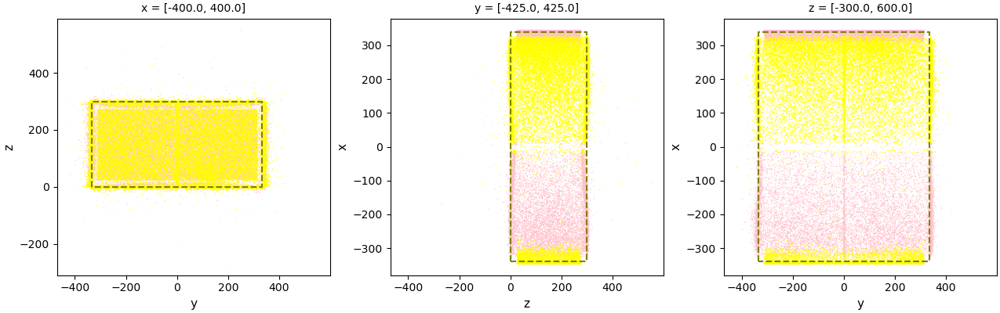

In [12]:
step=3
# plot_detector_slices_T(start_points[::step,0], start_points[::step,1], start_points[::step,2], 
#                      end_points[::step,0], end_points[::step,1], end_points[::step,2], 1, ch=4, cw=4.5)
plot_detector_slices(start_points[~cathode_crosser][::step,0], start_points[~cathode_crosser][::step,1], start_points[~cathode_crosser][::step,2], 
                     end_points[~cathode_crosser][::step,0], end_points[~cathode_crosser][::step,1], end_points[~cathode_crosser][::step,2], 1, ch=4, cw=4.25)

print(len(start_points[::step,0]))
print(len(start_points[:,0]))

## Interior Points

Total no of start, end point pairs 121518 121518
No. of start points inside active volume by more than 30 cm : 8924
No. of end points inside active volume by more than 30 cm : 29170
No. of tracks with either start or end point inside active volume by more than 30 cm : 37626
No. of tracks with both start or end point inside active volume by more than 30 cm : 468

No. of only-anode-crossers' start points inside active volume by more than 30 cm : 8751
No. of only-anode-crossers' end points inside active volume by more than 30 cm : 28355
No. of anode-only-crossers with either start or end point inside active volume by more than 30 cm : 36640 / 110980 ( 0.330 )
No. of anode-cathode-crossers with either start or end point inside active volume by more than 30 cm : 986 / 10538 ( 0.094 )

No. of start points outside active volume by more than 30 cm : 215
No. of end points outside active volume by more than 30 cm : 363
36640
466


Text(0.5, 0, 'z [cm]')

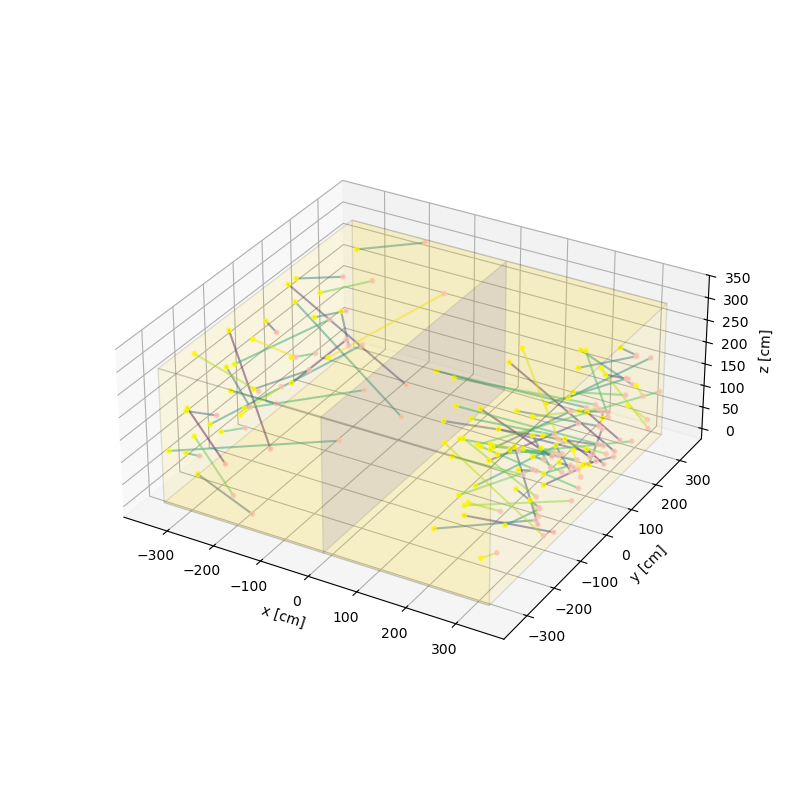

In [13]:
margin = 30 #cm

active_v_lower_bounds = np.array([av_bounds[0] for ax, av_bounds in ACTIVE_VOLUME_BOUNDS.items()])
active_v_upper_bounds = np.array([av_bounds[1] for ax, av_bounds in ACTIVE_VOLUME_BOUNDS.items()])

inside_axs_bounds_by_margin = lambda points_arr : ((points_arr - active_v_lower_bounds) > margin) & ((active_v_upper_bounds - points_arr) > margin) 
outside_axs_bounds_by_margin = lambda points_arr : ((active_v_lower_bounds - points_arr) > margin) | ((points_arr - active_v_upper_bounds) > margin) 

s_int_volume = np.all(inside_axs_bounds_by_margin(start_points), axis=1)
e_int_volume = np.all(inside_axs_bounds_by_margin(end_points), axis=1)  

print("Total no of start, end point pairs", len(start_points), len(end_points))
print(f"No. of start points inside active volume by more than {margin} cm :", 
      s_int_volume.sum() )
print(f"No. of end points inside active volume by more than {margin} cm :", 
      e_int_volume.sum() )
print(f"No. of tracks with either start or end point inside active volume by more than {margin} cm :", 
      (s_int_volume|e_int_volume).sum() )
print(f"No. of tracks with both start or end point inside active volume by more than {margin} cm :", 
      (s_int_volume&e_int_volume).sum() )
print()

print(f"No. of only-anode-crossers' start points inside active volume by more than {margin} cm :", 
      (s_int_volume&(~cathode_crosser)).sum() )
print(f"No. of only-anode-crossers' end points inside active volume by more than {margin} cm :", 
      (e_int_volume&(~cathode_crosser)).sum() )
print(f"No. of anode-only-crossers with either start or end point inside active volume by more than {margin} cm :", 
      f"{((s_int_volume|e_int_volume)&(~cathode_crosser)).sum()} / {(~cathode_crosser).sum()} ( {( ((s_int_volume|e_int_volume)&(~cathode_crosser)).sum() / (~cathode_crosser).sum() ):.3f} )")
print(f"No. of anode-cathode-crossers with either start or end point inside active volume by more than {margin} cm :", 
      f"{((s_int_volume|e_int_volume)&(cathode_crosser)).sum()} / {(cathode_crosser).sum()} ( {( ((s_int_volume|e_int_volume)&(cathode_crosser)).sum() / (cathode_crosser).sum() ):.3f} )")
print()

print(f"No. of start points outside active volume by more than {margin} cm :", 
      np.any(outside_axs_bounds_by_margin(start_points), axis=1).sum() )
print(f"No. of end points outside active volume by more than {margin} cm :", 
      np.any(outside_axs_bounds_by_margin(end_points), axis=1).sum() )


step = 400
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')
ax.set_box_aspect((677, 668, 300))
mask = ~(cathode_crosser)&(s_int_volume|e_int_volume)
print(mask.sum())
print((~(cathode_crosser)&(s_int_volume&e_int_volume)).sum())
ax.scatter(start_points[mask][::step, 0], 
           start_points[mask][::step, 1], 
           start_points[mask][::step, 2], 
           s=10, c="pink",   alpha=0.7)
ax.scatter(end_points[mask][::step, 0],   
           end_points[mask][::step, 1],   
           end_points[mask][::step, 2],   
           s=10, c="yellow", alpha=0.7)

from matplotlib import colormaps
for i in range(start_points[mask][::step].shape[0]):
    color = (*(colormaps['viridis'](i / start_points[mask][::step].shape[0])[:-1]), 0.5)
    ax.plot([start_points[mask][::step][i,0], end_points[mask][::step][i,0]], 
            [start_points[mask][::step][i,1], end_points[mask][::step][i,1]],
            [start_points[mask][::step][i,2], end_points[mask][::step][i,2]], ls="-", color=color)


ax.fill_between(338.5, (-334, -334, 334, 334, -334), (0, 300, 300, 0, 0), -338.5, (-334, -334, 334, 334, -334), (0, 300, 300, 0, 0), alpha=0.1, color='gold', edgecolor="k")
ax.fill_between(0, (-334, 334), 0, 0, (-334, 334), 300, alpha=0.1, color='blue', edgecolor="k")
ax.set_xlabel("x [cm]")
ax.set_ylabel("y [cm]")
ax.set_zlabel("z [cm]")



array([[-342.97296143,   47.01190186,  243.2749939 ],
       [-342.80062866,  152.03855896,  144.99499512],
       [-343.99404907, -134.38606262,   37.92551041],
       ...,
       [ 262.21481323,  344.2729187 ,  174.42500305],
       [ 243.36372375,  260.22113037,  143.46499634],
       [ 280.20587158,  170.00361633,   59.82500076]], shape=(121518, 3))

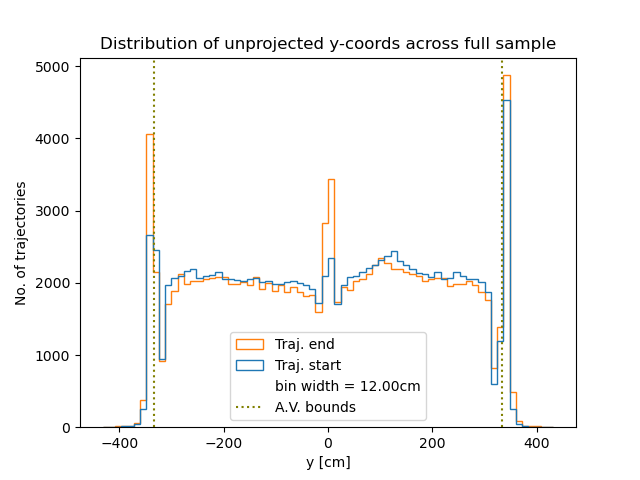

In [7]:
cc=cathode_crosser
plt.figure()
# plt.hist(start_points, histtype="step", stacked=False, bins="auto", label=["x", "y", "z"])
plt.title("Distribution of unprojected y-coords across full sample")

min_y = np.min([start_points[:,1], end_points[:,1]])
max_y = np.max([start_points[:,1], end_points[:,1]])
bw = 12
bin_edges = np.linspace( bw*np.floor(min_y / bw), bw*np.ceil(max_y / bw), int(np.ceil(max_y / bw) - np.floor(min_y / bw))+1)
# _, bins, _ = plt.hist([start_points[:,1], end_points[:,1]], histtype="step", stacked=False, bins="auto", label=["Traj. start", "Traj. end"])
_, bins, _ = plt.hist([start_points[:,1], end_points[:,1]], histtype="step", stacked=False, bins=bin_edges, label=["Traj. start", "Traj. end"])
plt.plot([],[]," ",label=f"bin width = {bins[1]-bins[0]:.2f}cm")
plt.axvline(-334, ls=":", color='olive', label="A.V. bounds")
plt.axvline(334, ls=":", color='olive')
plt.legend()
# plt.xlabel("Start-point coordinate")
plt.xlabel("y [cm]")
plt.ylabel("No. of trajectories")

# plt.figure()
# # plt.hist(end_points, histtype="step", stacked=False, bins="auto", label=["x", "y", "z"])
# plt.hist(end_points[:,1], histtype="step", stacked=False, bins="auto")
# plt.legend()
# # plt.xlabel("end-point coordinate")
# plt.xlabel("end-point y")


end_points

Text(0, 0.5, 'No. of trajectories')

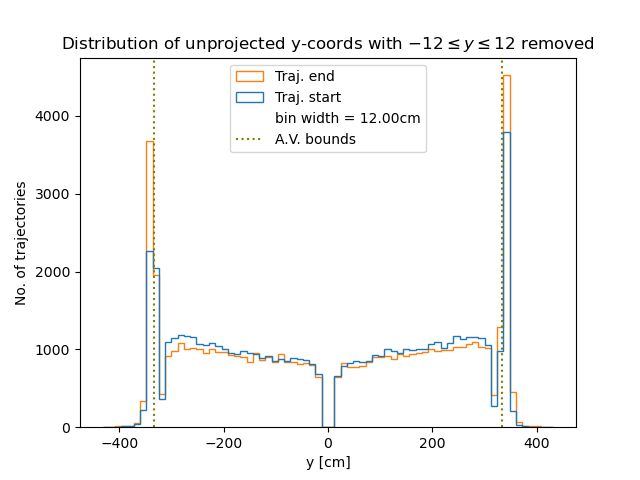

In [8]:
no_crp=excl_y_mask
plt.figure()
# plt.hist(start_points, histtype="step", stacked=False, bins="auto", label=["x", "y", "z"])
plt.title(r"Distribution of unprojected y-coords with $-12\leq y\leq 12$ removed")

min_y = np.min([start_points[:,1], end_points[:,1]])
max_y = np.max([start_points[:,1], end_points[:,1]])
bw = 12
bin_edges = np.linspace( bw*np.floor(min_y / bw), bw*np.ceil(max_y / bw), int(np.ceil(max_y / bw) - np.floor(min_y / bw))+1)

# _, bins, _ = plt.hist([start_points[no_crp][:,1], end_points[no_crp][:,1]], histtype="step", stacked=False, bins="auto", label=["Traj. start", "Traj. end"])
_, bins, _ = plt.hist([start_points[no_crp][:,1], end_points[no_crp][:,1]], histtype="step", stacked=False, bins=bin_edges, label=["Traj. start", "Traj. end"])
plt.plot([],[]," ",label=f"bin width = {bins[1]-bins[0]:.2f}cm")
plt.axvline(-334, ls=":", color='olive', label="A.V. bounds")
plt.axvline(334, ls=":", color='olive')
plt.legend()
# plt.xlabel("Start-point coordinate")
plt.xlabel("y [cm]")
plt.ylabel("No. of trajectories")

121518
121518


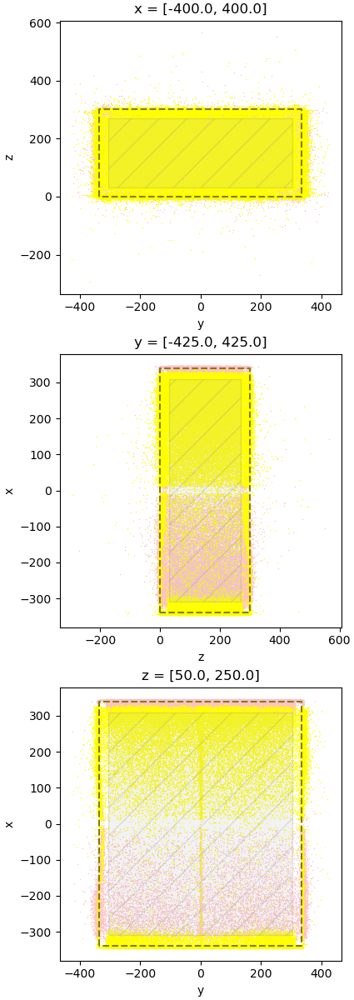

In [39]:
cc=cathode_crosser
plot_bounds = DETECTOR_BOUNDS.copy()
plot_bounds['z'] = (50, 250)


step=1
# plot_detector_slices_T(start_points[cc][::step,0], start_points[cc][::step,1], start_points[cc][::step,2], 
#                        end_points[cc][::step,0], end_points[cc][::step,1], end_points[cc][::step,2], 1, 
#                        ch=4, cw=4.25, margin=30, bounds_to_use=plot_bounds)
# plot_detector_slices_T(start_points[~cc][::step,0], start_points[~cc][::step,1], start_points[~cc][::step,2], 
#                        end_points[~cc][::step,0], end_points[~cc][::step,1], end_points[~cc][::step,2], 1, 
#                        ch=4, cw=4.25, margin=30, bounds_to_use=plot_bounds)
plot_detector_slices_T(start_points[::step,0], start_points[::step,1], start_points[::step,2], 
                       end_points[::step,0], end_points[::step,1], end_points[::step,2], 1, 
                       ch=4, cw=4.25, margin=30, bounds_to_use=plot_bounds)
# plot_detector_slices(start_points[~cc][::step,0], start_points[~cc][::step,1], start_points[~cc][::step,2], 
#                      end_points[~cc][::step,0], end_points[~cc][::step,1], end_points[~cc][::step,2], 1, 
#                      ch=4, cw=4.25, bounds_to_use=plot_bounds)

print(len(start_points[::step,0]))
print(len(start_points[:,0]))

121518
121518


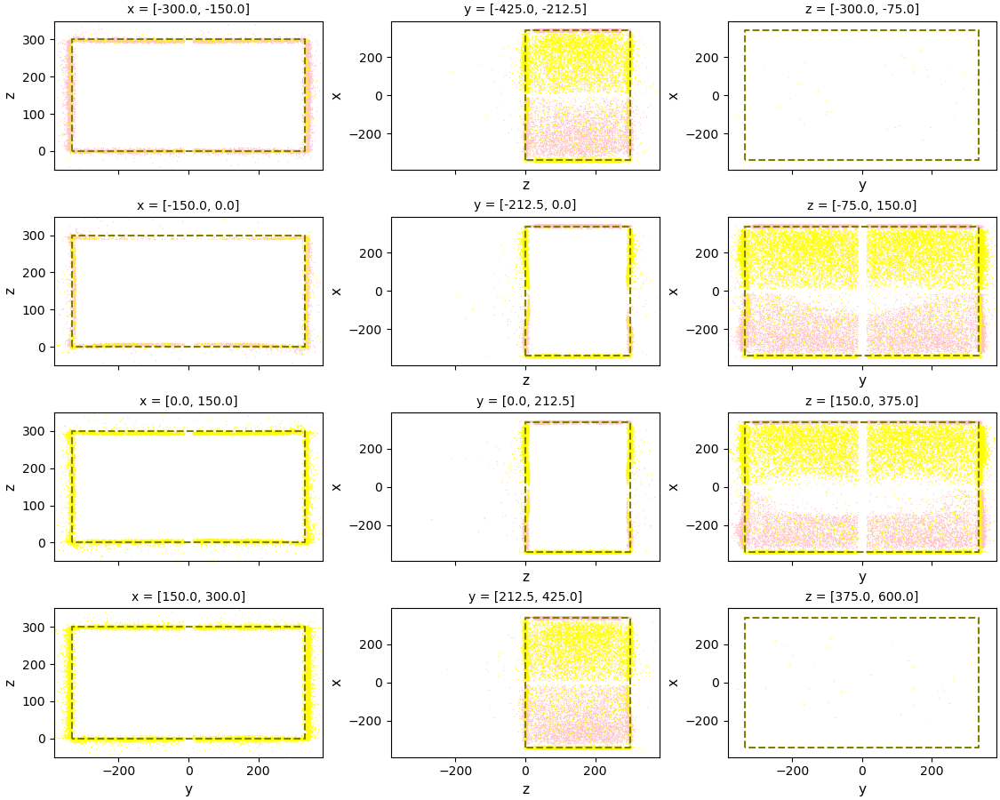

In [12]:
cc=cathode_crosser
plot_bounds = DETECTOR_BOUNDS.copy()
plot_bounds['x'] = (-300, 300)

step=1
# mask = cc
# mask = ~cc
# mask = np.ones_like(cc)
mask = excl_y_mask
# plot_detector_slices_T(start_points[mask][::step,0], start_points[mask][::step,1], start_points[mask][::step,2], 
#                        end_points[mask][::step,0], end_points[mask][::step,1], end_points[mask][::step,2], 4, 
#                        ch=2.5, cw=3.5, fixed_lims=True)
plot_detector_slices(start_points[mask][::step,0], start_points[mask][::step,1], start_points[mask][::step,2], 
                     end_points[mask][::step,0], end_points[mask][::step,1], end_points[mask][::step,2], 4, 
                     ch=2.25, cw=3.75, fixed_lims=True, bounds_to_use=plot_bounds)

print(len(start_points[::step,0]))
print(len(start_points[:,0]))

## Projection

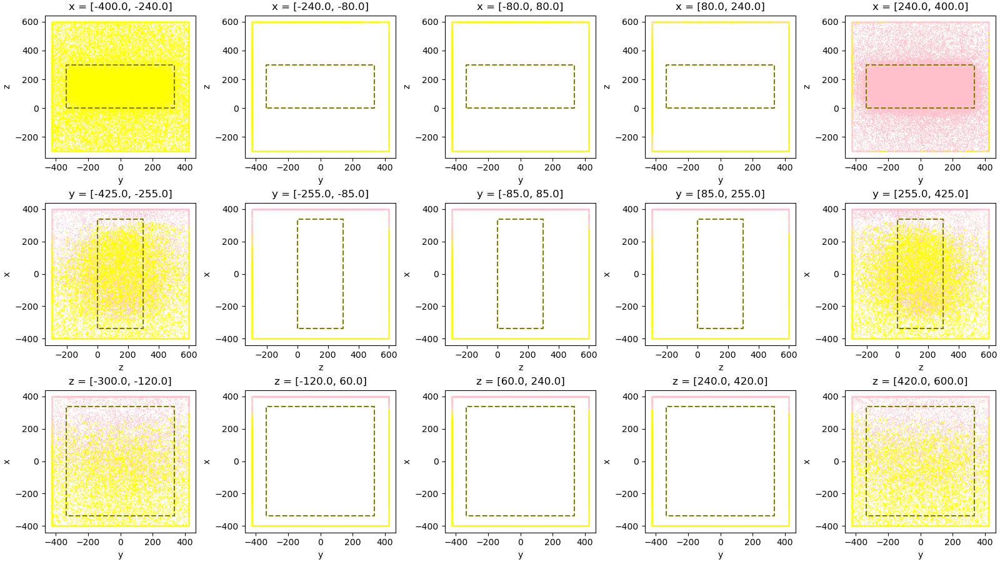

In [17]:
# plot_detector_slices(proj_start_points[:,0], proj_start_points[:,1], proj_start_points[:,2], 
#                      proj_end_points[:,0], proj_end_points[:,1], proj_end_points[:,2], 8)
plot_detector_slices_T(proj_start_points[:,0], proj_start_points[:,1], proj_start_points[:,2], 
                     proj_end_points[:,0], proj_end_points[:,1], proj_end_points[:,2], 5)

Text(0.5, 0, 'z [cm]')

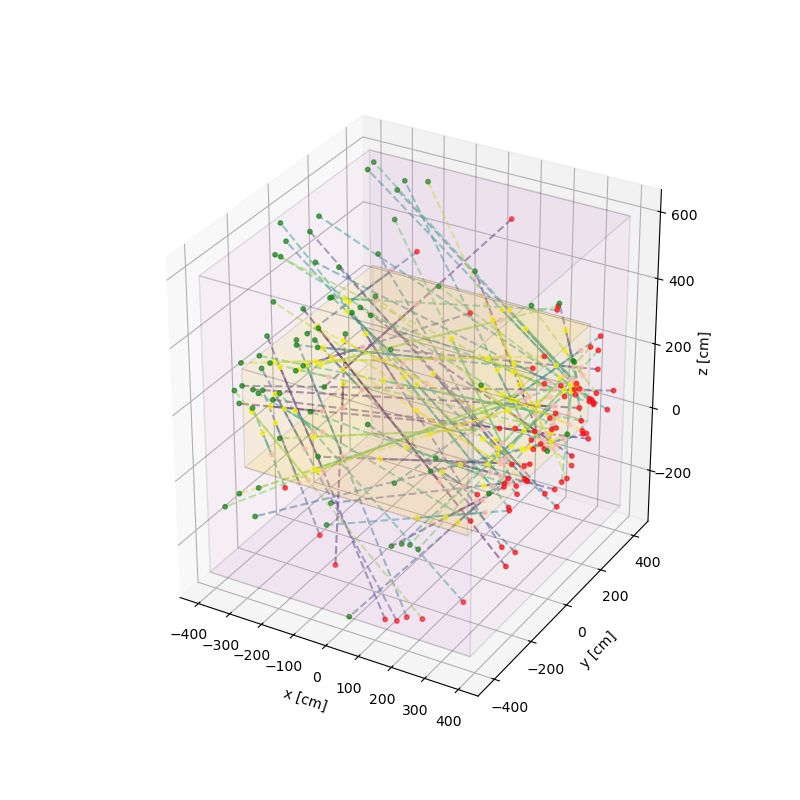

In [18]:
step = 1600
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')
ax.set_box_aspect((800, 850, 900))
ax.scatter(proj_start_points[::step, 0], proj_start_points[::step, 1], proj_start_points[::step, 2], s=10, c="red",    alpha=0.7)
ax.scatter(start_points[::step, 0],      start_points[::step, 1],      start_points[::step, 2],      s=10, c="pink",   alpha=0.7)
ax.scatter(end_points[::step, 0],        end_points[::step, 1],        end_points[::step, 2],        s=10, c="yellow", alpha=0.7)
ax.scatter(proj_end_points[::step, 0],   proj_end_points[::step, 1],   proj_end_points[::step, 2],   s=10, c="green",  alpha=0.7)

from matplotlib import colormaps
for i in range(start_points[::step].shape[0]):
    color = (*(colormaps['viridis'](i / start_points[::step].shape[0])[:-1]), 0.5)
    ax.plot([start_points[::step][i,0], end_points[::step][i,0]], 
            [start_points[::step][i,1], end_points[::step][i,1]],
            [start_points[::step][i,2], end_points[::step][i,2]], ls="-", color=color)
    ax.plot([proj_start_points[::step][i,0], proj_end_points[::step][i,0]], 
            [proj_start_points[::step][i,1], proj_end_points[::step][i,1]],
            [proj_start_points[::step][i,2], proj_end_points[::step][i,2]], ls="--", color=color)

ax.fill_between(338.5, (-334, -334, 334, 334, -334), (0, 300, 300, 0, 0), -338.5, (-334, -334, 334, 334, -334), (0, 300, 300, 0, 0), alpha=0.1, color='gold', edgecolor="k")
ax.fill_between(400, (-425, -425, 425, 425, -425), (-300, 600, 600, -300, -300), -400, (-425, -425, 425, 425, -425), (-300, 600, 600, -300, -300), alpha=0.1, color='plum', edgecolor="k")
# ax.fill_between(0, (-334, 334), 0, 0, (-334, 334), 300, alpha=0.1, edgecolor="k") # cathode plane 

ax.set_xlabel("x [cm]")
ax.set_ylabel("y [cm]")
ax.set_zlabel("z [cm]")


## Horizontal Tracks 

Text(0, 0.5, 'Delta-x over whole track')

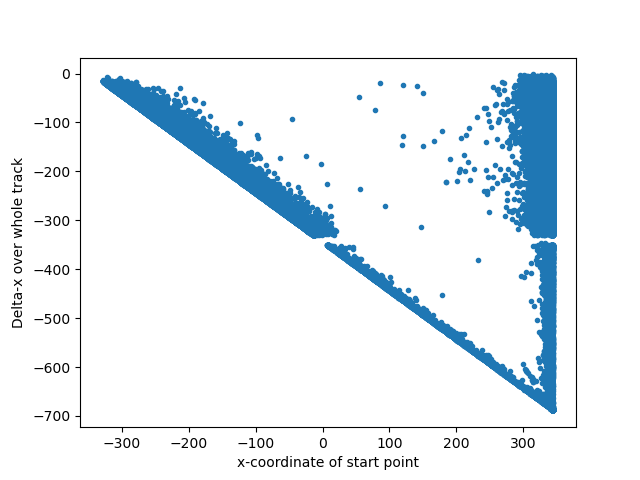

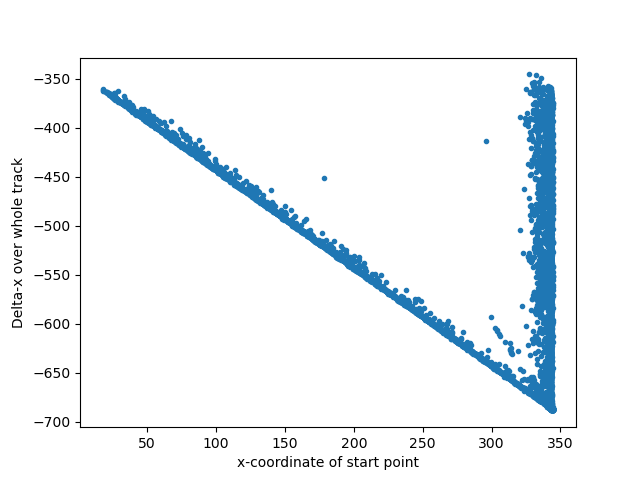

In [19]:
plt.figure()
plt.plot(start_points[:,0], end_points[:,0] - start_points[:,0], ".")
plt.xlabel("x-coordinate of start point")
plt.ylabel("Delta-x over whole track")

plt.figure()
plt.plot(start_points[cathode_crosser][:,0], end_points[cathode_crosser][:,0] - start_points[cathode_crosser][:,0], ".")
plt.xlabel("x-coordinate of start point")
plt.ylabel("Delta-x over whole track")

Given the track crosses at least one anode and the cathode, the second plot is exactly what we would expect. If the track crossed through the top anode, then its start point is near $x = +340$ and depending on its angle it may descend by at most $\Delta x \approx -680$ if it reached the bottom anode or by at least $\Delta x \approx -340$ since it needs to at least reach the cathode. That's the line at $x\approx340$

However if the track instead entered below the top anode i.e. its start-point $x < 340$, then in order to have been selected as a CA track it needs to reach the bottom anode, meaning its $\Delta x$ _has_ to be equal to (its starting $x - (-349)$). That's the diagonal.


The same logic applies to the first plot generally for all anode-crossers. If it entered in through the top anode ($x\approx340$), it is free to have any $\Delta x$ since the condition that it must cross at least one anode is already fulfilled.  

If it instead entered below the top anode, its $\Delta x$ is fixed to be the rest of the way to the bottom anode since it did gets selected as crossing at least one anode. 

**So this scatterplot alone doesn't tell you anything about the anomaly** of **a significant overabundance of tracks at the _top_ of the detector ($x \approx 350$) which cross near perfectly horizontally -- specifically, often roughly along the Y axis -- within the active volume (but most concentrated at the $z\approx100-200$ middle)**, which you saw in the voxel_occupancy analysis


Text(0, 0.5, 'Delta-z over whole track')

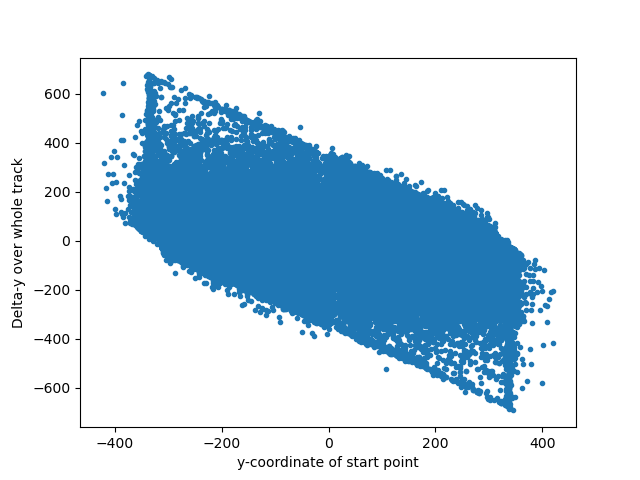

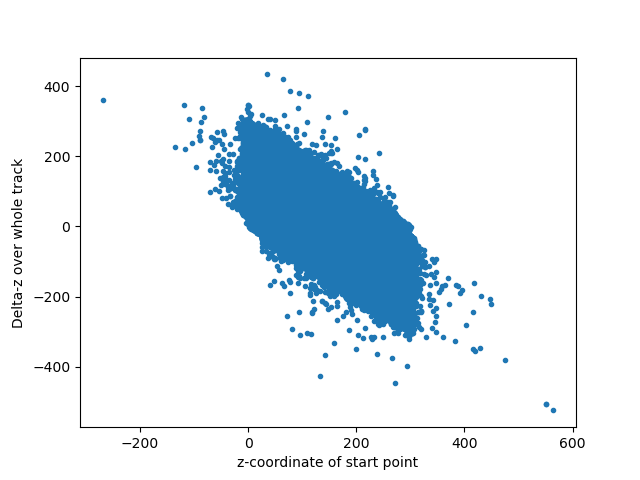

In [20]:
plt.figure()
plt.plot(start_points[:,1], end_points[:,1] - start_points[:,1], ".")
plt.xlabel("y-coordinate of start point")
plt.ylabel("Delta-y over whole track")

plt.figure()
plt.plot(start_points[:,2], end_points[:,2] - start_points[:,2], ".")
plt.xlabel("z-coordinate of start point")
plt.ylabel("Delta-z over whole track")

C:\Users\sansk\AppData\Local\Temp\ipykernel_24020\1497800170.py:37: RuntimeWarning: invalid value encountered in divide
  yz_slopes = (horizontal_delta_z) / (end_points[near_horizontal_tracks][:,1] - start_points[near_horizontal_tracks][:,1])


np.int64(21718)

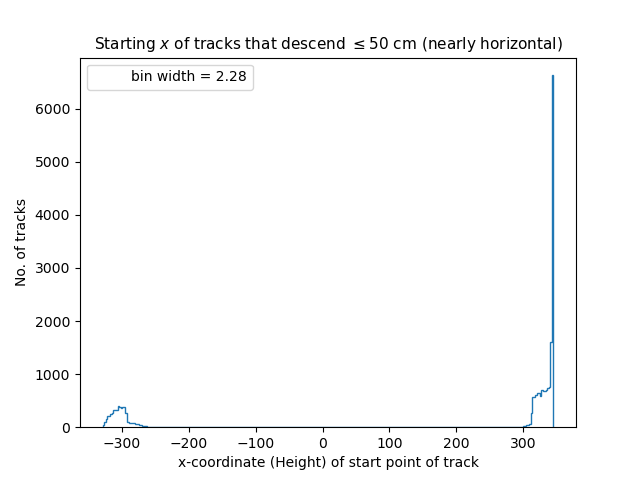

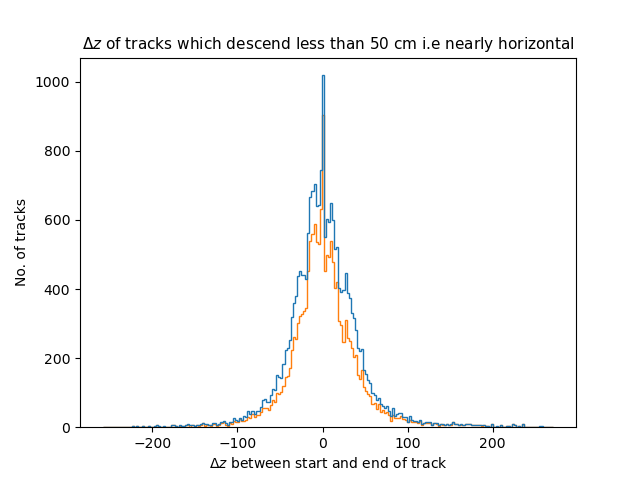

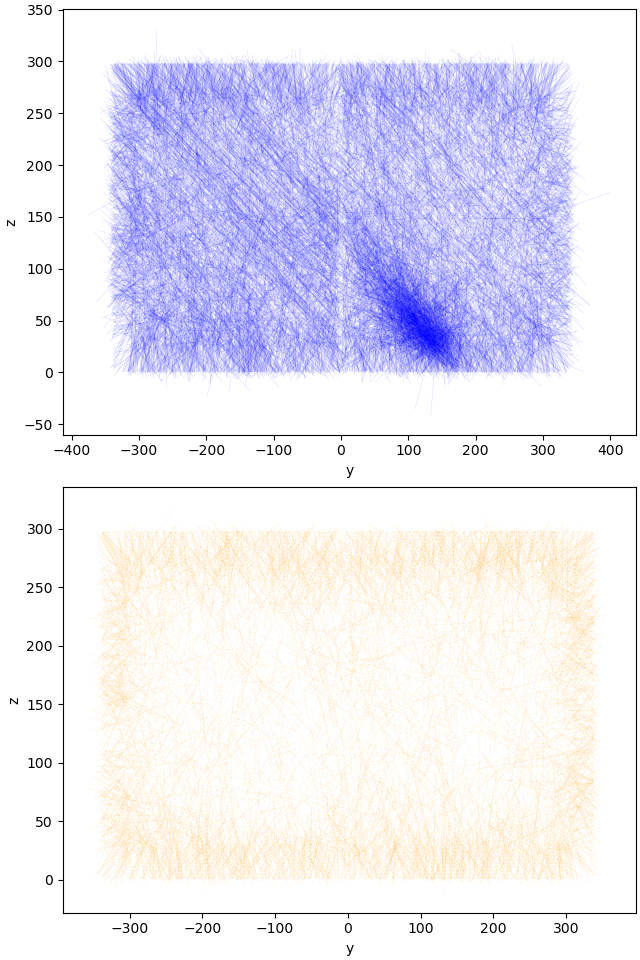

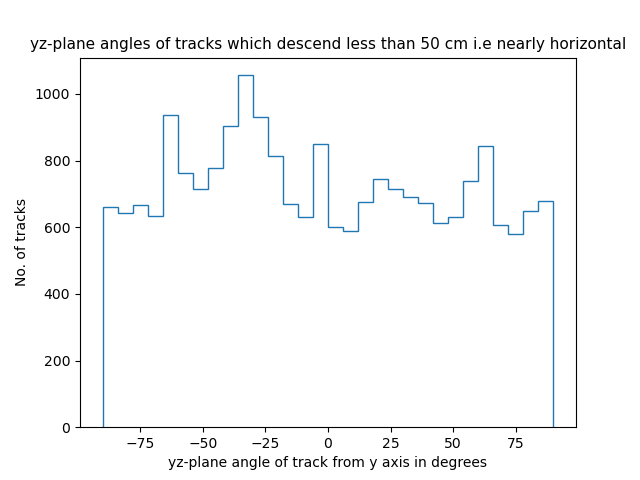

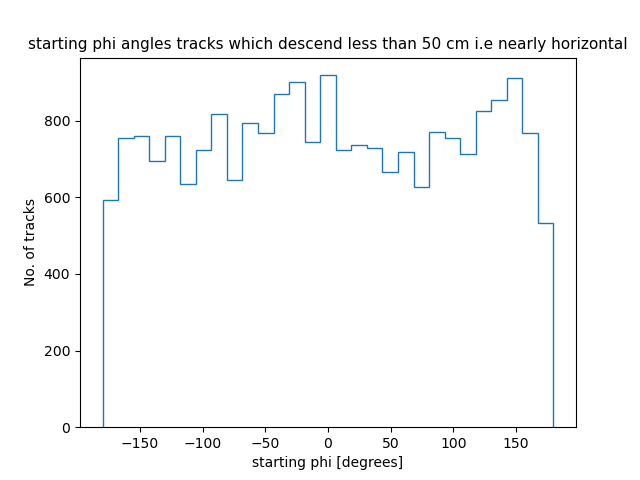

In [36]:
dxcut = 50
near_horizontal_tracks = np.abs(end_points[:,0] - start_points[:,0]) < dxcut #cm 

assert np.all(near_horizontal_tracks == (end_points[:,0] - start_points[:,0] > -dxcut)) #cm 
assert (start_points[:,0] > end_points[:,0]).all()

plt.figure()
start_x_hist = plt.hist(start_points[near_horizontal_tracks][:,0], histtype="step", bins="auto")
plt.plot([],[]," ",label=f"bin width = {start_x_hist[1][1] - start_x_hist[1][0]:.2f}")
plt.xlabel("x-coordinate (Height) of start point of track")
plt.ylabel("No. of tracks")
plt.title(f"Starting $x$ of tracks that descend $\leq {dxcut}$ cm (nearly horizontal)", fontsize=11)
plt.legend()

horizontal_delta_z = end_points[near_horizontal_tracks][:,2] - start_points[near_horizontal_tracks][:,2] 
plt.figure()
plt.hist([horizontal_delta_z, horizontal_delta_z[start_points[near_horizontal_tracks][:,0]>0]],  
         histtype="step", 
         bins="auto")
plt.xlabel(r"$\Delta z$ between start and end of track")
plt.ylabel("No. of tracks")
plt.title(f"$\\Delta z$ of tracks which descend less than {dxcut} cm i.e nearly horizontal", fontsize=11)

# from matplotlib import colormaps
fig, axs = plt.subplots(2, figsize=(6.4, 4.8*2), layout="constrained")
axs[0].set_xlabel("y")
axs[1].set_xlabel("y")
axs[0].set_ylabel("z")
axs[1].set_ylabel("z")
for i, (ini, end) in enumerate(zip(start_points[near_horizontal_tracks], end_points[near_horizontal_tracks])):
    if ini[0] > 0:
        axs[0].plot([ini[1], end[1]], [ini[2], end[2]], ls="-", lw=0.5, color="blue", alpha=0.1)
    else:
        axs[1].plot([ini[1], end[1]], [ini[2], end[2]], ls="--", lw=0.5, color="orange", alpha=0.1)

plt.figure()
yz_slopes = (horizontal_delta_z) / (end_points[near_horizontal_tracks][:,1] - start_points[near_horizontal_tracks][:,1])
plt.hist(np.arctan(yz_slopes) * (180/np.pi), histtype="step", bins="auto")
plt.xlabel("yz-plane angle of track from y axis in degrees")
plt.ylabel("No. of tracks")
plt.title(f"yz-plane angles of tracks which descend less than {dxcut} cm i.e nearly horizontal", fontsize=11)

plt.figure()
plt.hist(start_angles[near_horizontal_tracks][:, 1], histtype="step", bins="auto")
plt.xlabel("starting phi [degrees]")
plt.ylabel("No. of tracks")
plt.title(f"starting phi angles tracks which descend less than {dxcut} cm i.e nearly horizontal", fontsize=11)

near_horizontal_tracks.sum()

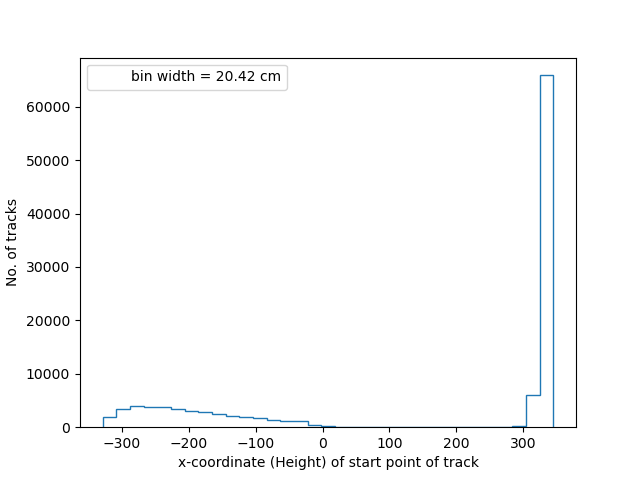

In [97]:
plt.figure()
start_x_hist = plt.hist(start_points[~cc][:,0], histtype="step", bins="auto")
plt.plot([],[]," ",label=f"bin width = {start_x_hist[1][1] - start_x_hist[1][0]:.2f} cm")
plt.xlabel("x-coordinate (Height) of start point of track")
plt.ylabel("No. of tracks")
plt.title(f"", fontsize=11)
plt.legend()

# fig, axs = plt.subplots(2, figsize=(6.4, 4.8*2), layout="constrained")
# axs[0].set_xlabel("y")
# axs[1].set_xlabel("y")
# axs[0].set_ylabel("z")
# axs[1].set_ylabel("z")
# for i, (ini, end) in enumerate(zip(start_points[~cc], end_points[~cc])):
#     if ini[0] > 0:
#         axs[0].plot([ini[1], end[1]], [ini[2], end[2]], ls="-", lw=0.5, color="blue", alpha=0.1)
#     else:
#         axs[1].plot([ini[1], end[1]], [ini[2], end[2]], ls="--", lw=0.5, color="orange", alpha=0.1)

In [22]:
# top_anode_plane_intersect_points = end_points + ((338.5 - end_points[:,0])/(end_points[:,0] - start_points[:,0]))[:,None]*(end_points - start_points)
# low_anode_plane_intersect_points = end_points + ((-338.5 - end_points[:,0])/(end_points[:,0] - start_points[:,0]))[:,None]*(end_points - start_points)
# print(np.unique_counts(top_anode_plane_intersect_points[:,0]))
# print(np.unique_counts(low_anode_plane_intersect_points[:,0]))

# # grace = 678 -- 679
# grace=0
# crosses_top_anode = (top_anode_plane_intersect_points[:,1]>=-334-grace)&(top_anode_plane_intersect_points[:,1]<=334+grace)&(top_anode_plane_intersect_points[:,2]>=0-grace)&(top_anode_plane_intersect_points[:,2]<=300+grace)
# crosses_low_anode = (low_anode_plane_intersect_points[:,1]>=-334-grace)&(low_anode_plane_intersect_points[:,1]<=334+grace)&(low_anode_plane_intersect_points[:,2]>=0-grace)&(low_anode_plane_intersect_points[:,2]<=300+grace)


# print(len(crosses_top_anode))
# print(np.sum(crosses_low_anode&crosses_top_anode))
# print(np.sum(crosses_low_anode&crosses_top_anode&cathode_crosser))

print( trk_info_table.read_where("(cc_is_anode_crosser==1)").size )
print( trk_info_table.read_where("(is_anode_crosser==1)").size )
print( trk_info_table.read_where("(is_anode_crosser==1)|(cc_is_anode_crosser==1)").size )
print( trk_info_table.read_where("(is_anode_crosser==1)&(cc_is_anode_crosser==1)").size )

print()
print( trk_info_table.read_where("(cathode_crosser_ID!=-1)&(cc_is_anode_crosser==1)").size )
print( trk_info_table.read_where("(cathode_crosser_ID!=-1)&(is_anode_crosser==1)").size )
print( trk_info_table.read_where("(cathode_crosser_ID!=-1)&( (is_anode_crosser==1) | (cc_is_anode_crosser==1) )").size )


7032
130307
135929
1410

7032
5964
11586


**None of the tracks in the histogram above were in the AC/CA/ACA sample, because in order for a track to cross the cathode and at least one anode, its $\Delta x$ must be at least 338.5**

## Can we find the beam

Text(0, 0.5, 'Number of trajectories')

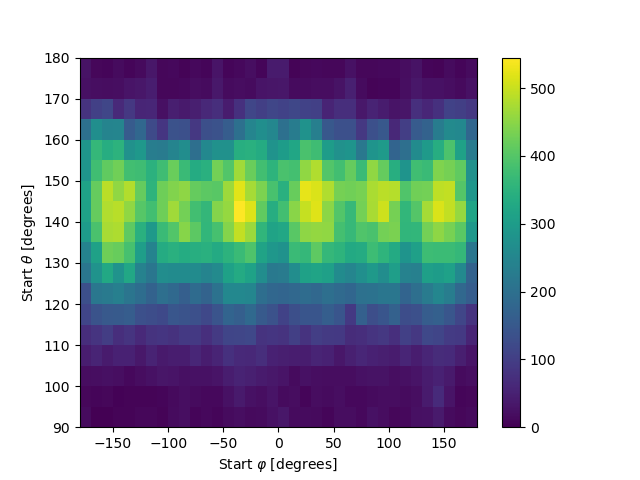

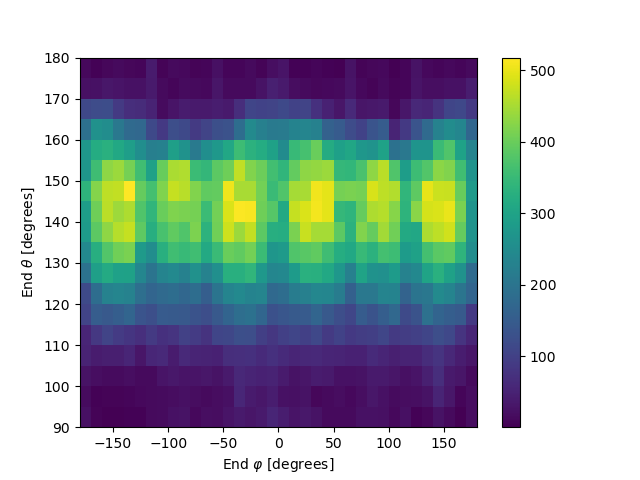

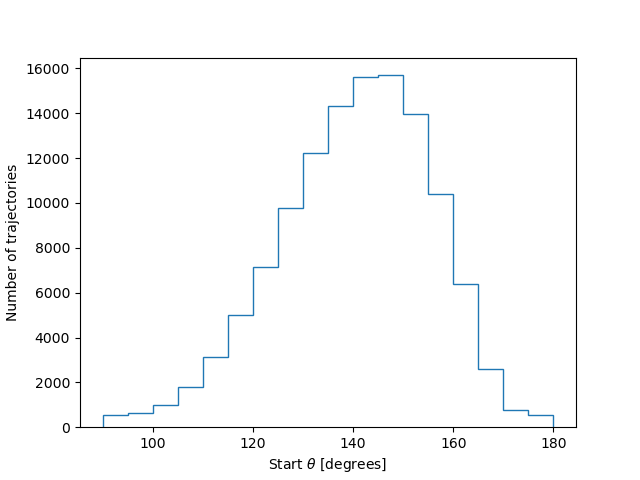

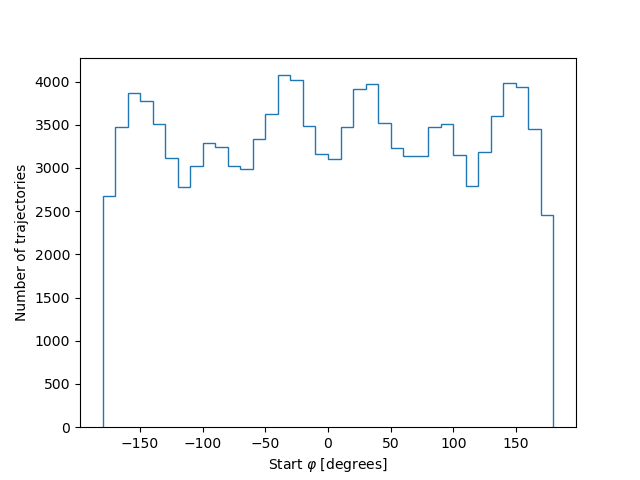

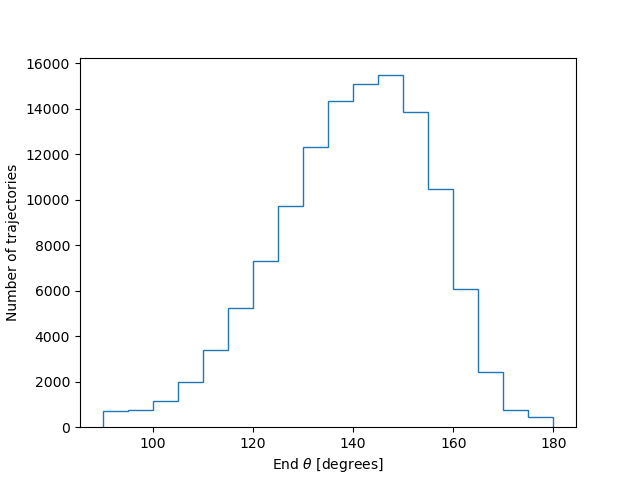

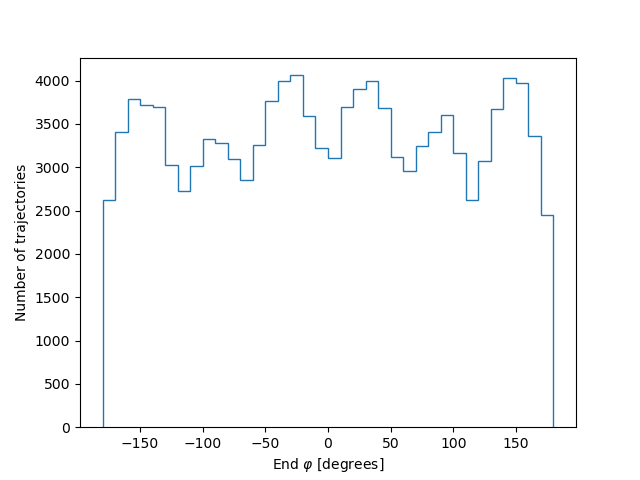

In [87]:
phi_bw = 10 # degrees
phi_bin_edges = np.linspace(-180, 180, (360 // phi_bw)+1)
theta_bw = 5 # degrees
theta_bin_edges = np.linspace(90, 180, (90 // theta_bw)+1)

plt.figure()
_,_,_,im = plt.hist2d(start_angles[:,1], 
           start_angles[:,0], 
           bins=[phi_bin_edges, theta_bin_edges])
plt.colorbar(im)
plt.xlabel(r"Start $\varphi$ [degrees]")
plt.ylabel(r"Start $\theta$ [degrees]")

plt.figure()
_,_,_,im = plt.hist2d(end_angles[:,1], 
           end_angles[:,0], 
           bins=[phi_bin_edges, theta_bin_edges])
plt.colorbar(im)
plt.xlabel(r"End $\varphi$ [degrees]")
plt.ylabel(r"End $\theta$ [degrees]")


plt.figure()
plt.hist(start_angles[:,0], 
        bins=theta_bin_edges, histtype='step')
plt.xlabel(r"Start $\theta$ [degrees]")
plt.ylabel(r"Number of trajectories")

plt.figure()
plt.hist(start_angles[:,1], 
        bins=phi_bin_edges, histtype='step')
plt.xlabel(r"Start $\varphi$ [degrees]")
plt.ylabel(r"Number of trajectories")

plt.figure()
plt.hist(end_angles[:,0], 
        bins=theta_bin_edges, histtype='step')
plt.xlabel(r"End $\theta$ [degrees]")
plt.ylabel(r"Number of trajectories")

plt.figure()
plt.hist(end_angles[:,1], 
        bins=phi_bin_edges, histtype='step')
plt.xlabel(r"End $\varphi$ [degrees]")
plt.ylabel(r"Number of trajectories")


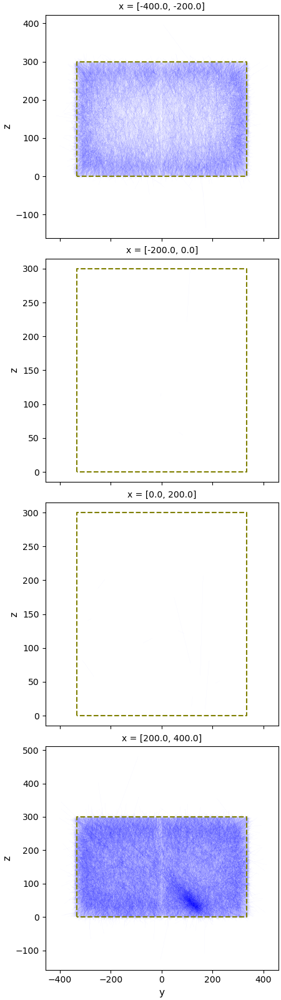

In [16]:
plot_detector_slices_alt(start_points[:,0], start_points[:,1], start_points[:,2], 
                     end_points[:,0], end_points[:,1], end_points[:,2], 4, step=1, x_only=True)

# RUN 43993

In [4]:
trk_info_file_2 = tab.open_file("out_43993_a_ac_ca_aca.h5")

In [5]:
trk_info_table_2 = trk_info_file_2.root.output
trk_info_table_2

/output (Table(np.int64(128510),)) np.str_('Output (test)')
  description := {
  "filename": StringCol(itemsize=36, shape=(), dflt=np.bytes_(b''), pos=0),
  "event": UInt32Col(shape=(), dflt=np.uint32(0), pos=1),
  "trigger": UInt32Col(shape=(), dflt=np.uint32(0), pos=2),
  "cluster_ID": Int32Col(shape=(), dflt=np.int32(0), pos=3),
  "ID": UInt32Col(shape=(), dflt=np.uint32(0), pos=4),
  "cathode_crosser_ID": Int32Col(shape=(), dflt=np.int32(0), pos=5),
  "total_npe": Float64Col(shape=(), dflt=np.float64(0.0), pos=6),
  "cluster_size": UInt32Col(shape=(), dflt=np.uint32(0), pos=7),
  "cc_is_anode_crosser": BoolCol(shape=(), dflt=np.False_, pos=8),
  "is_anode_crosser": BoolCol(shape=(), dflt=np.False_, pos=9),
  "cc_is_cathode_crosser": BoolCol(shape=(), dflt=np.False_, pos=10),
  "is_cathode_crosser": BoolCol(shape=(), dflt=np.False_, pos=11),
  "cc_x_ini": Float32Col(shape=(), dflt=np.float32(0.0), pos=12),
  "x_ini": Float32Col(shape=(), dflt=np.float32(0.0), pos=13),
  "cc_x_end": 

In [ ]:
anode_only_crosser_ct = 0
anode_only_crosser_oob_ct = 0

anode_cathode_crosser_ct = 0
anode_cathode_crosser_oob_ct = 0
anode_cathode_crosser_bad_join_ct = 0

bad_join_cc_ini = []
bad_join_cc_end = []
bad_join_ini = []
bad_join_end = []

for track in trk_info_table_2:
    reco_track_point_bounds = DETECTOR_BOUNDS.copy()
    reco_track_point_bounds['x'] = (-345, 345) # The (lardon z) (larsoft x) values are computed from e drift times referenced to estimated t0 (actual track-crossing time). It should be impossible to get a (larsoft) x significantly outside active volume unless t0 estimation is wrong (if the first e- reached the anode "before the track even crossed"). 
    # Maybe the y and z bounds should also be stricter --> how does LARDON determine x_ini/end and y_ini/end? Would it be reasonable for these values to be outside detector volume?
    # LArSoft (x,y,z) <---> LARDON (z,x,y)
    coords = {}
    coords["x_ini"], coords["y_ini"], coords["z_ini"] = track['z_ini_corrected'], track['x_ini'], track['y_ini']  
    coords["x_end"], coords["y_end"], coords["z_end"] = track['z_end_corrected'], track['x_end'], track['y_end']  

    is_paired = (track["cathode_crosser_ID"] != -1)
    if is_paired:
        anode_cathode_crosser_ct += 1
        # The "cc_"-labelled tracks are supposed to be the ones in the upper volume.  
        coords["cc_x_ini"], coords["cc_y_ini"], coords["cc_z_ini"] = track['cc_z_ini_corrected'], track['cc_x_ini'], track['cc_y_ini'] 
        coords["cc_x_end"], coords["cc_y_end"], coords["cc_z_end"] = track['cc_z_end_corrected'], track['cc_x_end'], track['cc_y_end'] 

        ## Perform "quality control" tests
        # If any of the four points lie outside the allowed bounds, exit.
        exit_flag = False
        for ax, bounds in reco_track_point_bounds.items():
            if np.any( [ ((coords[k] < bounds[0]) or (coords[k] > bounds[1])) for k in (f"cc_{ax}_ini",f"cc_{ax}_end",f"{ax}_ini",f"{ax}_end") ] ):
                exit_flag = True
        if exit_flag: 
            anode_cathode_crosser_oob_ct += 1
            continue

        # If the "cc_" (upper volume) track starts _below_ the start of the paired *lower* volume track (or ends below its end), something is wrong.
        # Basically if one track completely overlaps vertically with the other or the tracks are "on the wrong side", move on.    
        if (coords["cc_x_ini"] < coords["x_ini"]) or (coords["cc_x_end"] < coords["x_end"]):
            anode_cathode_crosser_bad_join_ct += 1
            bad_join_cc_ini.append([coords["cc_x_ini"], coords["cc_y_ini"], coords["cc_z_ini"]])
            bad_join_cc_end.append([coords["cc_x_end"], coords["cc_y_end"], coords["cc_z_end"]])
            bad_join_ini.append([coords["x_ini"], coords["y_ini"], coords["z_ini"]])
            bad_join_end.append([coords["x_end"], coords["y_end"], coords["z_end"]])
            continue
        # Note: at this point the cc_ini --> end distance ought to be the largest among the four points involved. Can check this externally 
    else:
        anode_only_crosser_ct += 1
        # If any of the four points lie outside the allowed bounds, exit.
        exit_flag = False
        for ax, bounds in reco_track_point_bounds.items():
            if np.any( [ ((coords[k] < bounds[0]) or (coords[k] > bounds[1])) for k in (f"{ax}_ini",f"{ax}_end") ] ):
                exit_flag = True
        if exit_flag: 
            anode_only_crosser_oob_ct += 1
            continue

anode_only_crosser_filt_ct = anode_only_crosser_ct - anode_only_crosser_oob_ct
anode_cathode_crosser_filt_ct = anode_cathode_crosser_ct - anode_cathode_crosser_oob_ct - anode_cathode_crosser_bad_join_ct

print("No. of selected tracks", anode_only_crosser_ct + anode_cathode_crosser_ct)
# ^ Total number of rows in output table. All the rows obtained through read_where(track_selection_condition) where track_selection_condition is pds_match_condition & <anode/cathode crosser checker> 
# Is 135929 for Run 39273
print("-->filtered for oob", anode_only_crosser_oob_ct+anode_cathode_crosser_oob_ct)
print("-->filtered for bad join", anode_cathode_crosser_bad_join_ct)
print("-->remaining", anode_only_crosser_filt_ct + anode_cathode_crosser_filt_ct)

print("No. of selected anode-only tracks", anode_only_crosser_ct)
print("-->filtered for oob", anode_only_crosser_oob_ct)
print("-->remaining", anode_only_crosser_filt_ct)

print("No. of selected anode-cathode tracks", anode_cathode_crosser_ct)
print("-->filtered for oob", anode_cathode_crosser_oob_ct)
print("-->filtered for bad join", anode_cathode_crosser_bad_join_ct)
print("-->remaining", anode_cathode_crosser_filt_ct)

bad_join_cc_ini = np.array(bad_join_cc_ini)
bad_join_cc_end = np.array(bad_join_cc_end)
bad_join_ini = np.array(bad_join_ini)
bad_join_end = np.array(bad_join_end)


No. of selected tracks 128510
-->filtered for oob 8603
-->filtered for bad join 4
-->remaining 119903
No. of selected anode-only tracks 110994
-->filtered for oob 7178
-->remaining 103816
No. of selected anode-cathode tracks 17516
-->filtered for oob 1425
-->filtered for bad join 4
-->remaining 16087
